In [1]:
import stardist
import bin2cell as b2c
import matplotlib.pyplot as plt
import scanpy as sc
import numpy as np
import os
import squidpy as sq
import pandas as pd
os.makedirs("stardist", exist_ok=True)
print(os.getcwd())

__init__.py (31): The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.


/Users/mayathompson/anaconda_projects/a3c73d36-db0d-42f4-af0b-8e0bf8513471


utils.py (434): Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.


In [2]:
path = "/Users/mayathompson/research/MIA1/square_002um"
source_image_path = "/Users/mayathompson/research/MIA1/MIA-1-ICI-R.hires.jpg"
spaceranger_image_path = "/Users/mayathompson/research/MIA1/spatial"

In [3]:
adata = b2c.read_visium(path, 
                        source_image_path = source_image_path, 
                        spaceranger_image_path = spaceranger_image_path
                       )
adata.var_names_make_unique()
adata

anndata.py (1758): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
anndata.py (1758): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


AnnData object with n_obs × n_vars = 11222500 × 18085
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'

In [4]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_counts=1)
adata

AnnData object with n_obs × n_vars = 5605079 × 18027
    obs: 'in_tissue', 'array_row', 'array_col', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    uns: 'spatial'
    obsm: 'spatial'

In [5]:
mpp = 0.3

b2c.scaled_he_image(adata, mpp=mpp, save_path="/Users/mayathompson/research/MIA1/stardist/he.tiff") 

Cropped spatial coordinates key: spatial_cropped_150_buffer
Image key: 0.3_mpp_150_buffer


In [7]:
b2c.destripe(adata)

_construct.py (163): Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`


2385376454.py (9): Use `squidpy.pl.spatial_scatter` instead.
anndata.py (1138): Trying to modify attribute `.var` of view, initializing view as actual.
anndata.py (1138): Trying to modify attribute `.var` of view, initializing view as actual.


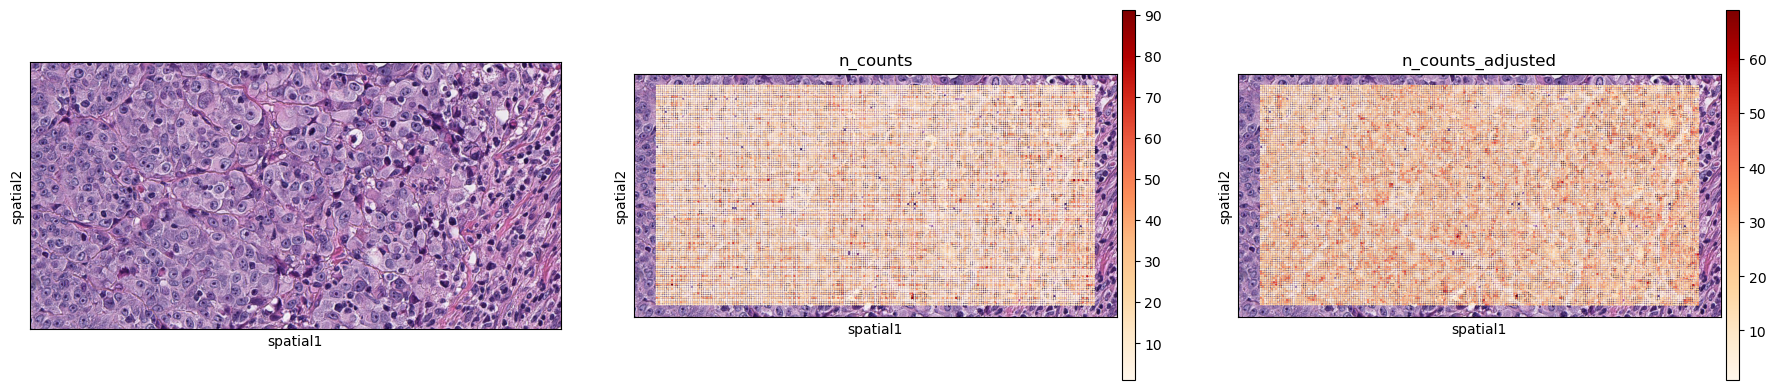

In [8]:
#define a mask to easily pull out this region of the object in the future
mask = ((adata.obs['array_row'] >= 1450) & 
        (adata.obs['array_row'] <= 1550) & 
        (adata.obs['array_col'] >= 250) & 
        (adata.obs['array_col'] <= 450)
       )

bdata = adata[mask]
sc.pl.spatial(bdata, color=[None, "n_counts", "n_counts_adjusted"], color_map="OrRd",
              img_key="0.3_mpp_150_buffer")

3840311323.py (1): Use `squidpy.pl.spatial_scatter` instead.


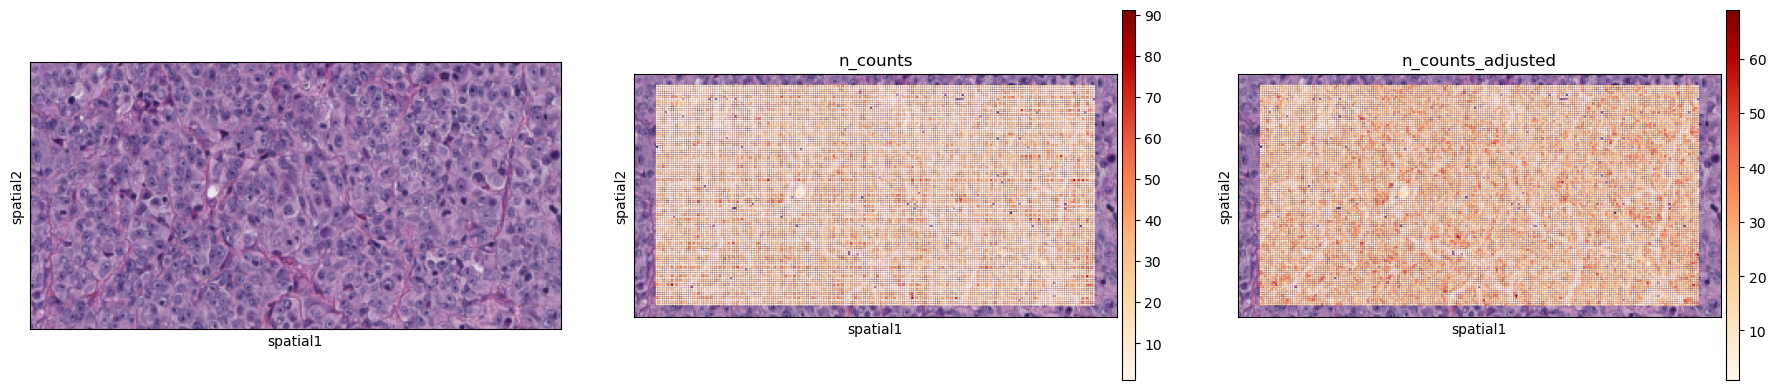

In [9]:
sc.pl.spatial(bdata, color=[None, "n_counts", "n_counts_adjusted"], color_map="OrRd")

In [10]:
b2c.stardist(image_path="/Users/mayathompson/research/MIA1/stardist/he.tiff", #changed
             labels_npz_path="/Users/mayathompson/research/MIA1/stardist/he.npz", #changed
             stardist_model="2D_versatile_he", 
             prob_thresh=0.01
            )

Found model '2D_versatile_he' for 'StarDist2D'.
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.692478, nms_thresh=0.3.
effective: block_size=(4096, 4096, 3), min_overlap=(128, 128, 0), context=(128, 128, 0)


100%|███████████████████████████████████████████| 36/36 [27:45<00:00, 46.27s/it]


Found 361363 objects


In [11]:
b2c.insert_labels(adata, 
                  labels_npz_path="/Users/mayathompson/research/MIA1/stardist/he.npz", 
                  basis="spatial", 
                  spatial_key="spatial_cropped_150_buffer",
                  mpp=mpp, 
                  labels_key="labels_he"
                 )

4204209659.py (5): Trying to modify attribute `.obs` of view, initializing view as actual.
4204209659.py (7): Use `squidpy.pl.spatial_scatter` instead.


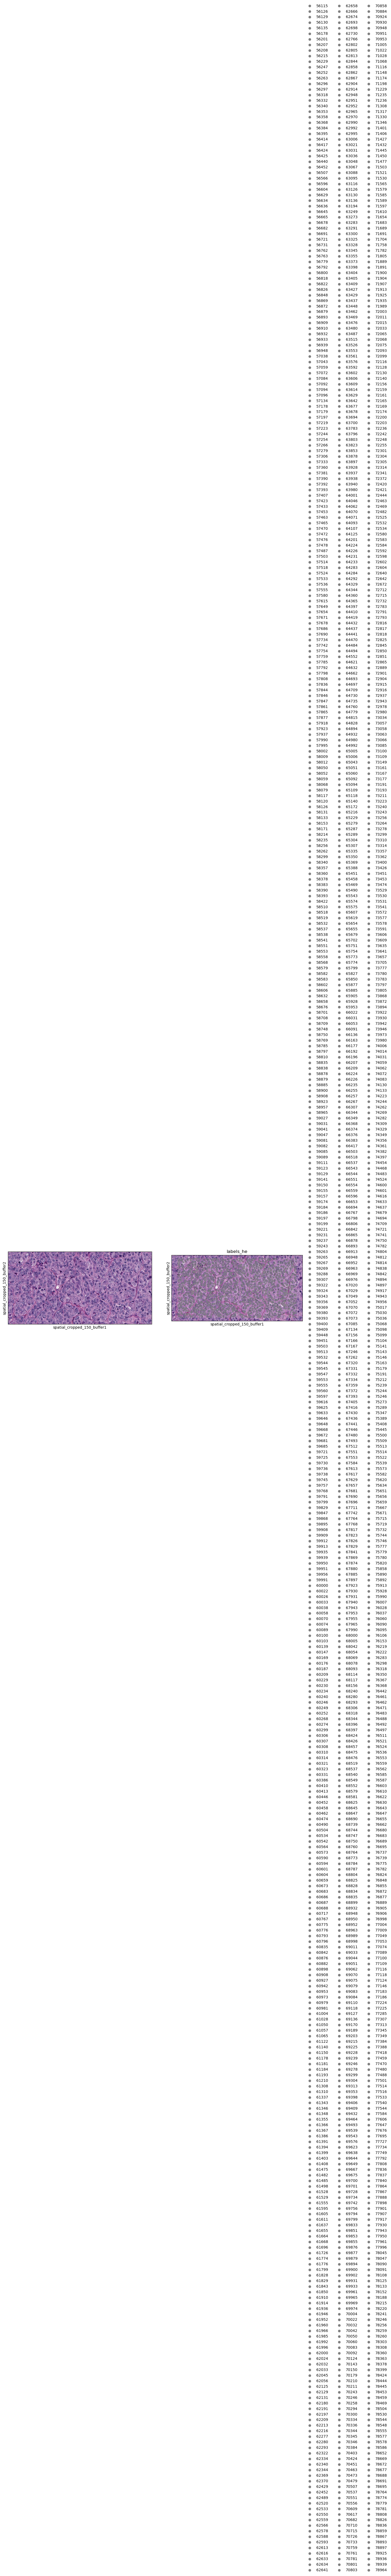

In [12]:
bdata = adata[mask]

#the labels obs are integers, 0 means unassigned
bdata = bdata[bdata.obs['labels_he']>0]
bdata.obs['labels_he'] = bdata.obs['labels_he'].astype(str)

sc.pl.spatial(bdata, color=[None, "labels_he"], img_key="0.3_mpp_150_buffer", basis="spatial_cropped_150_buffer")

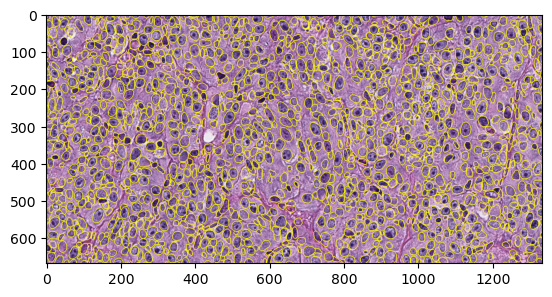

In [13]:
#the label viewer wants a crop of the processed image
#get the corresponding coordinates spanning the subset object
crop = b2c.get_crop(bdata, basis="spatial", spatial_key="spatial_cropped_150_buffer", mpp=mpp)

rendered = b2c.view_labels(image_path="/Users/mayathompson/research/MIA1/stardist/he.tiff", 
                           labels_npz_path="/Users/mayathompson/research/MIA1/stardist/he.npz", 
                           crop=crop
                          )
plt.imshow(rendered)

In [14]:
import os
os.environ["KMP_WARNINGS"] = "0"
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import scanpy as sc
from collections import deque
from sklearn.neighbors import NearestNeighbors
from tqdm.notebook import tqdm

N_PCS = 20
MAX_BINS = 200
MAX_PERIMETER_MICRONS = 4.0
mpp = 0.3  # microns per pixel

In [15]:
# log transformation
if not hasattr(adata, "log1p_done"):
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata.log1p_done = True

sc.pp.pca(adata, n_comps=N_PCS, mask_var=None)

# compute pca
pca = adata.obsm['X_pca']

# extract pca and spatial coords 
coords = np.array(adata.obsm['spatial'])
coords_um = coords * mpp  # convert to microns
n_bins = adata.n_obs
labels = adata.obs['labels_he'].to_numpy() # original nucleus labels, convert to numpy for efficiency

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [16]:
# create nearest neighbors graph (9, for 8 neighboring bins)
nbrs = NearestNeighbors(n_neighbors=9, algorithm='ball_tree').fit(coords_um)
_, indices = nbrs.kneighbors(coords_um)
neighbors = indices[:, 1:]  # exclude self

In [17]:
# create array to store current owner
current_owner = np.zeros(n_bins, dtype=int)

# create array to store distance to owner in PCA space
owner_dist = np.full(n_bins, np.inf)

nucleus_labels = np.unique(labels)
nucleus_labels = nucleus_labels[nucleus_labels > 0]

# fix bins already assigned to nucleus (cannot be reassigned)
for lbl in nucleus_labels:
    idx = np.flatnonzero(labels == lbl)
    current_owner[idx] = lbl
    owner_dist[idx] = 0

In [18]:
# create a perimeter of 1 bin
b2c.expand_labels(
    adata,
    labels_key='labels_he',
    expanded_labels_key='labels_he_perimeter',
    max_bin_distance=1  # perimeter = 1 bin
)

In [ ]:
# MAX_PERIMETER in microns
MAX_PERIMETER = MAX_PERIMETER_MICRONS

for nucleus_label in tqdm(nucleus_labels, desc="Expanding nuclei", ncols=80, mininterval=0.1):
    
    # original nucleus bins
    nucleus_idx = np.flatnonzero(labels == nucleus_label)
    
    # average PCA of the nucleus (pca of centroiid)
    nucleus_pca_centroid = pca[nucleus_idx].mean(axis=0)
    dists_pca = np.linalg.norm(pca[nucleus_idx] - nucleus_pca_centroid, axis=1) # dist of each nucleus bin from centroid in PCA space 
    pca_threshold = np.percentile(dists_pca, 90)

    # perimeter
    perimeter_bins = np.flatnonzero(adata.obs['labels_he_perimeter'] == nucleus_label)
    queue = deque(perimeter_bins) # start from perim and move outwards
    
    bin_count = len(nucleus_idx)
    
    while queue:
        if bin_count >= MAX_BINS:
            break
        
        bin_idx = queue.popleft()
        # removed skipping bins already owned to allow competitive reassignment
        
        # ensures bin falls within 4 microns of perimeter (phsycial dist)
        dist_to_perimeter = np.min(np.linalg.norm(coords_um[perimeter_bins] - coords_um[bin_idx], axis=1))
        if dist_to_perimeter > MAX_PERIMETER:
            continue
        
        # checks if bin falls within PCA threshold
        dist_pca = np.linalg.norm(pca[bin_idx] - nucleus_pca_centroid)
        if dist_pca > pca_threshold:
            continue
        
        # reassign bin if closer in PCA to this nuclei than prev owner
        if dist_pca < owner_dist[bin_idx]:
            current_owner[bin_idx] = nucleus_label
            owner_dist[bin_idx] = dist_pca
            bin_count += 1
            
            # add neighbors to queue
            for n in neighbors[bin_idx]:
                queue.append(n)

adata.obs['labels_pca_expanded'] = current_owner
adata.obs['labels_pca_owner_dist'] = owner_dist

adata.write("/Users/mayathompson/research/MIA1/MIA1_adata.h5ad") 

Expanding nuclei:   0%|                              | 0/326697 [00:00<?, ?it/s]

/var/folders/5n/hr5nkt0j2bv_kc5j232fsbnc0000gn/T/ipykernel_97228/1144690689.py:11: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  bdata.obs['labels_pca_expanded'] = bdata.obs['labels_pca_expanded'].astype(str)
/var/folders/5n/hr5nkt0j2bv_kc5j232fsbnc0000gn/T/ipykernel_97228/1144690689.py:13: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


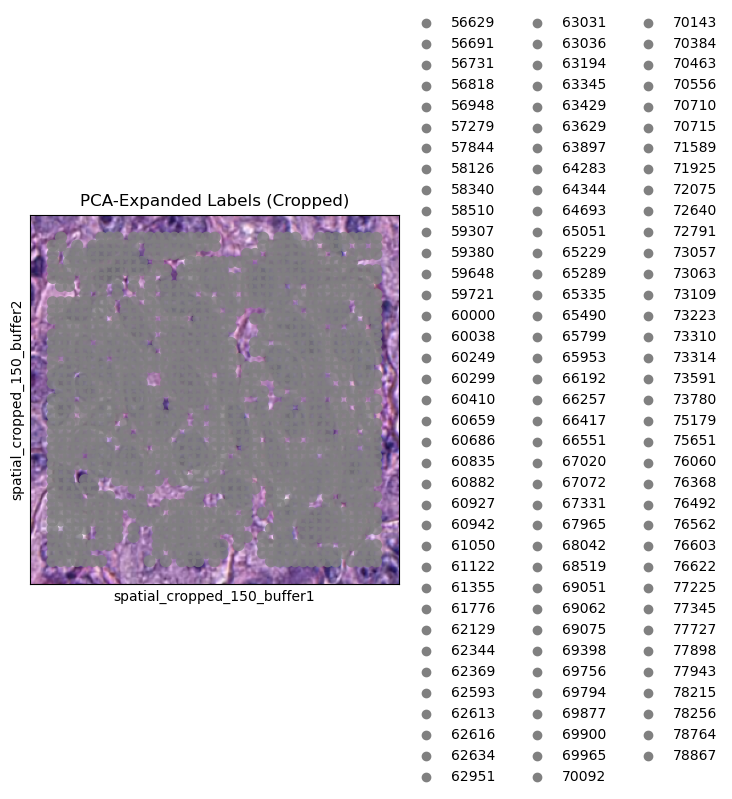

In [4]:
import scanpy as sc
adata = sc.read("/Users/mayathompson/research/MIA1/MIA1_adata.h5ad")
mask_zoom = ((adata.obs['array_row'] >= 1480) & 
        (adata.obs['array_row'] <= 1520) & 
        (adata.obs['array_col'] >= 330) & 
        (adata.obs['array_col'] <= 370)
       )

bdata = adata[mask_zoom].copy()
bdata = bdata[bdata.obs['labels_pca_expanded'] > 0]
bdata.obs['labels_pca_expanded'] = bdata.obs['labels_pca_expanded'].astype(str)

sc.pl.spatial(
    bdata,
    color='labels_pca_expanded',
    img_key='0.3_mpp_150_buffer',
    basis="spatial_cropped_150_buffer",
    size=1.5,
    alpha=0.8,
    title="PCA-Expanded Labels (Cropped)"
)

/var/folders/5n/hr5nkt0j2bv_kc5j232fsbnc0000gn/T/ipykernel_97228/482563117.py:11: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  bdata.obs['labels_pca_expanded'] = bdata.obs['labels_pca_expanded'].astype(str)
/var/folders/5n/hr5nkt0j2bv_kc5j232fsbnc0000gn/T/ipykernel_97228/482563117.py:13: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


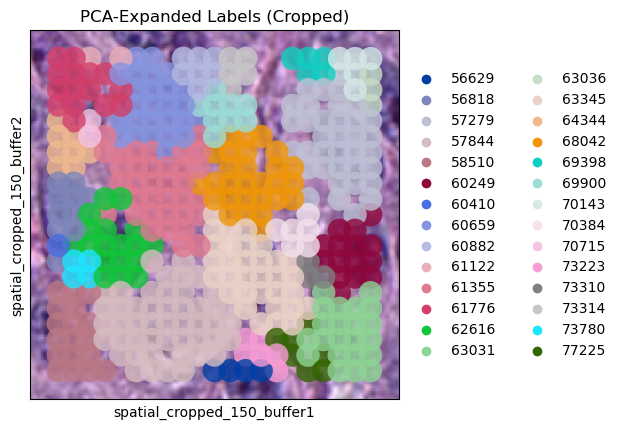

In [5]:
mask_zoom_2 = (
    (adata.obs['array_row'] >= 1490) & 
    (adata.obs['array_row'] <= 1510) & 
    (adata.obs['array_col'] >= 340) & 
    (adata.obs['array_col'] <= 360)
)

adata = sc.read("/Users/mayathompson/research/MIA1/MIA1_adata.h5ad")
bdata = adata[mask_zoom_2].copy()
bdata = bdata[bdata.obs['labels_pca_expanded'] > 0]
bdata.obs['labels_pca_expanded'] = bdata.obs['labels_pca_expanded'].astype(str)

sc.pl.spatial(
    bdata,
    color='labels_pca_expanded',
    img_key='0.3_mpp_150_buffer',
    basis="spatial_cropped_150_buffer",
    size=1.5,
    alpha=0.8,
    title="PCA-Expanded Labels (Cropped)"
)

In [1]:
import bin2cell as b2c
import scanpy as sc

adata = sc.read_h5ad("/Users/mayathompson/research/MIA1/MIA1_adata.h5ad") 

In [2]:
mpp = 0.3  
b2c.grid_image(adata, "n_counts_adjusted", mpp=mpp, sigma=5, save_path="/Users/mayathompson/research/MIA1/stardist/MIA1_gex.tiff")

In [3]:
b2c.stardist(
    image_path="/Users/mayathompson/research/MIA1/stardist/MIA1_gex.tiff",
    labels_npz_path="/Users/mayathompson/research/MIA1/stardist/MIA1_gex_pca_expanded.npz",
    stardist_model="2D_versatile_fluo",
    prob_thresh=0.05,
    nms_thresh=0.5
)

Found model '2D_versatile_fluo' for 'StarDist2D'.
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.479071, nms_thresh=0.3.
effective: block_size=(4096, 4096), min_overlap=(128, 128), context=(128, 128)


100%|████████████████████████████████████████| 36/36 [1:48:14<00:00, 180.41s/it]


Found 618517 objects


In [4]:
b2c.insert_labels(adata, 
                  labels_npz_path="/Users/mayathompson/research/MIA1/stardist/MIA1_gex_pca_expanded.npz", 
                  basis="array", 
                  mpp=mpp, 
                  labels_key="labels_gex"
                 )

b2c.salvage_secondary_labels(adata, 
                             primary_label="labels_pca_expanded", 
                             secondary_label="labels_gex", 
                             labels_key="labels_joint"
                            )

adata.write("/Users/mayathompson/research/MIA1/MIA1_adata_gex.h5ad")

Salvaged 194352 secondary labels
